# Day 2 · 실습: Patch Embedding과 Attention 시각화

**연계 이론:** 이론 3 「Vision Transformer의 구조」 · 이론 4 「Self-Attention의 계산 원리」

Patch 분할·Embedding의 Shape을 확인하고, 교육용 Q·K·V로 Attention Matrix를 계산합니다.
Projection과 Token 관련 가중치는 무작위 초기화되며, 사전학습 ViT의 실제 Attention은 아닙니다.

## 1. 이미지와 Tensor 준비

**연계 이론:** 이론 3 · 2.1

`IMAGE_PATH`를 비우면 실습용 도형 이미지를 생성합니다.

PyTorch: 2.15.0
이미지 Shape (N, C, H, W): (1, 3, 224, 224)


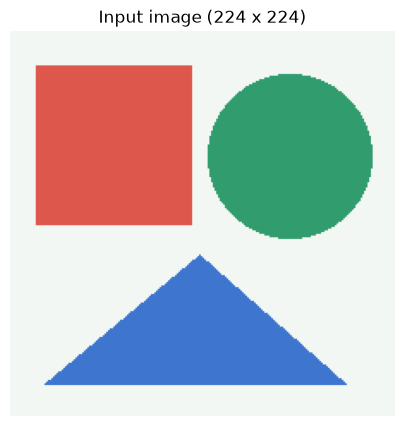

In [1]:
from pathlib import Path
import math

import numpy as np
import torch
from torch import nn
from torch.nn import functional as F
from PIL import Image, ImageDraw
import matplotlib.pyplot as plt

SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)

IMAGE_SIZE = 224
IMAGE_PATH = ""  # 변경해 보기: "sample.jpg" 또는 비워 두기

if IMAGE_PATH.strip():
    path = Path(IMAGE_PATH)
    if not path.is_file():
        raise FileNotFoundError(f"이미지 파일을 확인하세요: {path}")
    image = Image.open(path).convert("RGB").resize((224, 224))
else:
    image = Image.new("RGB", (224, 224), (242, 247, 243))
    draw = ImageDraw.Draw(image)
    draw.rectangle((15, 20, 105, 112), fill=(222, 87, 76))
    draw.ellipse((115, 25, 210, 120), fill=(49, 156, 109))
    draw.polygon(
        [(20, 205), (110, 130), (195, 205)],
        fill=(62, 118, 207)
    )

image_tensor = (
    torch.from_numpy(np.asarray(image).copy())
    .permute(2, 0, 1)
    .float()
    .div(255)
    .unsqueeze(0)
)

print("PyTorch:", torch.__version__)
print("이미지 Shape (N, C, H, W):", tuple(image_tensor.shape))

assert image_tensor.shape == (1, 3, 224, 224)

plt.figure(figsize=(5, 5))
plt.imshow(image)
plt.title("Input image (224 x 224)")
plt.axis("off")
plt.show()

## 2. Patch Size에 따른 이미지 분할

**연계 이론:** 이론 3 · 2.1~2.3, 7.4

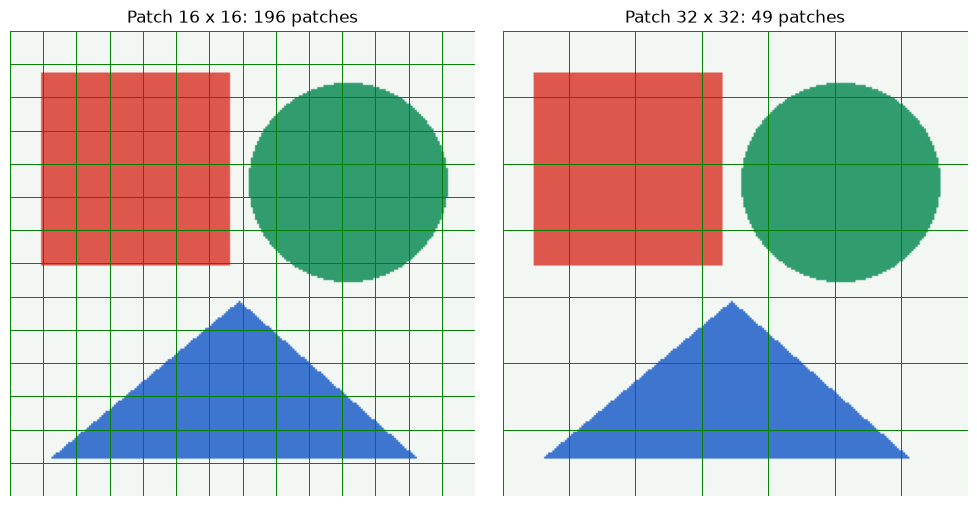

16x16: 196 개 / 32x32: 49 개


In [2]:
PATCH_SIZES = [16, 32]  # 변경해 보기: [8, 16, 32]

fig, axes = plt.subplots(
    1,
    len(PATCH_SIZES),
    figsize=(5 * len(PATCH_SIZES), 5)
)
axes = np.atleast_1d(axes)

for ax, patch_size in zip(axes, PATCH_SIZES):
    if IMAGE_SIZE % patch_size:
        raise ValueError("Patch Size는 224를 나눌 수 있어야 합니다.")

    n_side = IMAGE_SIZE // patch_size
    ax.imshow(image)

    for pos in range(0, IMAGE_SIZE + 1, patch_size):
        ax.axhline(pos - 0.5, color="green", linewidth=0.7)
        ax.axvline(pos - 0.5, color="green", linewidth=0.7)

    ax.set_title(
        f"Patch {patch_size} x {patch_size}: {n_side**2} patches"
    )
    ax.axis("off")

plt.tight_layout()
plt.show()

print(
    "16x16:", (224 // 16)**2, "개 /",
    "32x32:", (224 // 32)**2, "개"
)

## 3. Patch Flatten

**연계 이론:** 이론 3 · 3.1~3.2

In [3]:
def extract_patches(x, patch_size):
    # (N, 3, 224, 224) → (N, Patch 수, 3 * Patch Size**2)
    return F.unfold(
        x,
        kernel_size=patch_size,
        stride=patch_size
    ).transpose(1, 2)


flat16 = extract_patches(image_tensor, 16)
flat32 = extract_patches(image_tensor, 32)

print("Patch 16 Flatten:", tuple(flat16.shape))
print("Patch 32 Flatten:", tuple(flat32.shape))

assert flat16.shape == (1, 196, 768)
assert flat32.shape == (1, 49, 3072)

Patch 16 Flatten: (1, 196, 768)
Patch 32 Flatten: (1, 49, 3072)


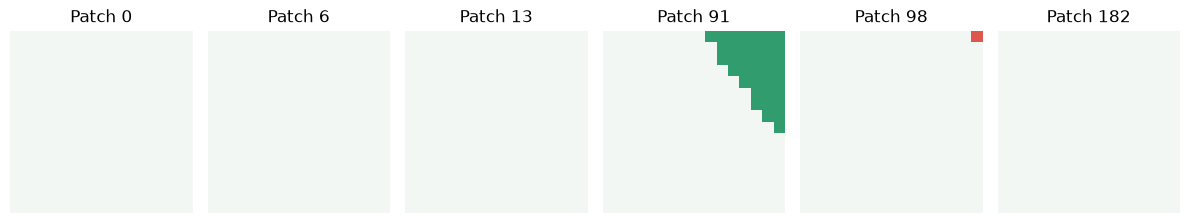

In [4]:
# 실제 이미지에서 잘라낸 Patch를 확인합니다.

SELECTED_PATCHES = [0, 6, 13, 91, 98, 182]
# 변경해 보기: 0~195

fig, axes = plt.subplots(
    1,
    len(SELECTED_PATCHES),
    figsize=(12, 2.5)
)
axes = np.atleast_1d(axes)

for ax, idx in zip(axes, SELECTED_PATCHES):
    patch = (
        flat16[0, idx]
        .reshape(3, 16, 16)
        .permute(1, 2, 0)
    )

    ax.imshow(patch.numpy())
    ax.set_title(f"Patch {idx}")
    ax.axis("off")

plt.tight_layout()
plt.show()

## 4. Patch Embedding과 CLS Token

**연계 이론:** 이론 3 · 3.3, 4.2~4.3

CLS Token을 먼저 연결한 뒤 모든 Token에 Positional Embedding을
더하는 순서를 확인합니다.

In [5]:
EMBED_DIM = 768

projection16 = nn.Linear(3 * 16 * 16, EMBED_DIM)
projection32 = nn.Linear(3 * 32 * 32, EMBED_DIM)

with torch.no_grad():
    embedding16 = projection16(flat16)
    embedding32 = projection32(flat32)

print("Patch 16 Embedding:", tuple(embedding16.shape))
print("Patch 32 Embedding:", tuple(embedding32.shape))

assert embedding16.shape == (1, 196, 768)
assert embedding32.shape == (1, 49, 768)

print("주의: 무작위 초기화된 Projection이며 학습된 특징이 아닙니다.")

Patch 16 Embedding: (1, 196, 768)
Patch 32 Embedding: (1, 49, 768)
주의: 무작위 초기화된 Projection이며 학습된 특징이 아닙니다.


In [6]:
def add_cls_and_position(embeddings):
    batch, token_count, dim = embeddings.shape

    cls_token = nn.Parameter(
        torch.randn(1, 1, dim) * 0.02
    )

    pos_embedding = nn.Parameter(
        torch.randn(1, token_count + 1, dim) * 0.02
    )

    cls_batch = cls_token.expand(batch, -1, -1)

    tokens = torch.cat(
        [cls_batch, embeddings],
        dim=1
    )

    return tokens + pos_embedding


encoder16 = add_cls_and_position(embedding16)
encoder32 = add_cls_and_position(embedding32)

print(
    "CLS + Position, Patch 16:",
    tuple(encoder16.shape)
)
print(
    "CLS + Position, Patch 32:",
    tuple(encoder32.shape)
)

assert encoder16.shape == (1, 197, 768)
assert encoder32.shape == (1, 50, 768)

CLS + Position, Patch 16: (1, 197, 768)
CLS + Position, Patch 32: (1, 50, 768)


## 5. Q·K·V와 Scaled Dot-Product Attention

**연계 이론:** 이론 4 · 2.1~2.3, 3.4, 4.2, 5.1~5.6

이론 4의 두 Token 계산 예제를 그대로 재현합니다.

In [7]:
Q = torch.tensor([
    [1., 0.],
    [0., 1.]
])

K = torch.tensor([
    [1., 0.],
    [0., 1.]
])

V = torch.tensor([
    [2., 0.],
    [0., 4.]
])

# 1. Query와 Key의 내적
scores = Q @ K.T

# 2. Scaling
scaled_scores = scores / math.sqrt(Q.shape[-1])

# 3. Softmax
weights = torch.softmax(scaled_scores, dim=-1)

# 4. Value 가중합
outputs = weights @ V

print("1. 내적 Score:\n", scores)
print("2. Scaling 후:\n", scaled_scores)
print("3. Softmax 가중치:\n", weights)
print("4. 가중합 출력:\n", outputs)
print("각 행의 합:", weights.sum(dim=-1))

# Token A 검증
assert torch.allclose(
    weights[0],
    torch.tensor([.670, .330]),
    atol=.002
)

assert torch.allclose(
    outputs[0],
    torch.tensor([1.34, 1.32]),
    atol=.01
)

# Token B 검증
assert torch.allclose(
    weights[1],
    torch.tensor([.330, .670]),
    atol=.002
)

assert torch.allclose(
    outputs[1],
    torch.tensor([.66, 2.68]),
    atol=.01
)

# 각 Query의 Attention Weight 합이 1인지 확인
assert torch.allclose(
    weights.sum(dim=-1),
    torch.ones(2),
    atol=1e-6
)

1. 내적 Score:
 tensor([[1., 0.],
        [0., 1.]])
2. Scaling 후:
 tensor([[0.7071, 0.0000],
        [0.0000, 0.7071]])
3. Softmax 가중치:
 tensor([[0.6698, 0.3302],
        [0.3302, 0.6698]])
4. 가중합 출력:
 tensor([[1.3395, 1.3210],
        [0.6605, 2.6790]])
각 행의 합: tensor([1., 1.])


## 6. Attention Heatmap

**연계 이론:** 이론 4 · 5.7, 7.1~7.2

행은 Query, 열은 Key입니다.
아래 시각화는 교육용 Attention Weight이며 실제 ViT의
Attention 결과가 아닙니다.

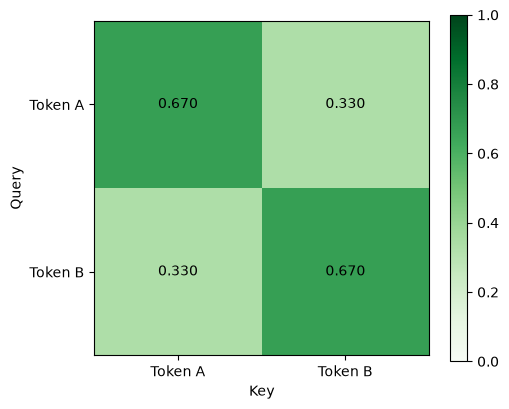

In [8]:
heat = weights.detach().numpy()

fig, ax = plt.subplots(figsize=(5.4, 4.5))

im = ax.imshow(
    heat,
    cmap="Greens",
    vmin=0,
    vmax=1
)

ax.set_xticks([0, 1], ["Token A", "Token B"])
ax.set_yticks([0, 1], ["Token A", "Token B"])
ax.set_xlabel("Key")
ax.set_ylabel("Query")

for r in range(2):
    for c in range(2):
        ax.text(
            c, r,
            f"{heat[r, c]:.3f}",
            ha="center",
            va="center"
        )

fig.colorbar(im, ax=ax)
plt.show()

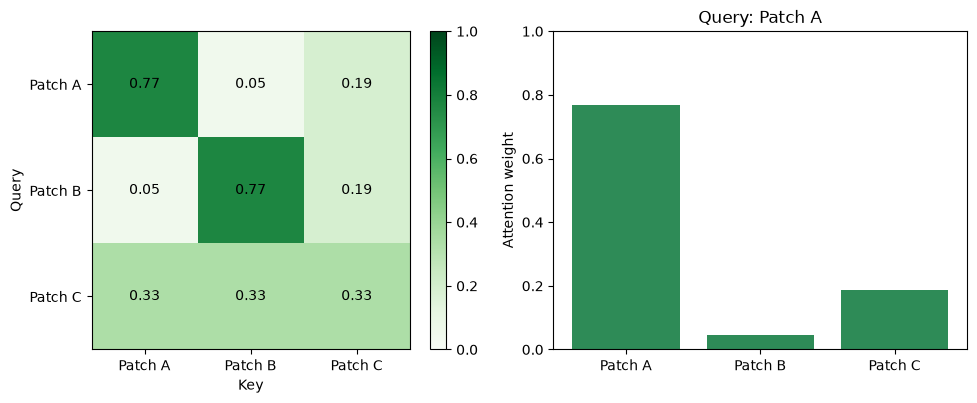

가중합 결과: tensor([0.9546, 0.2321])


In [9]:
# 6.1 세 Token으로 확장하여 Query별 Attention Weight 비교

labels = ["Patch A", "Patch B", "Patch C"]

Q3 = torch.tensor([
    [2., 0.],
    [0., 2.],
    [1., 1.]
])

K3 = Q3.clone()

V3 = torch.tensor([
    [1., 0.],
    [0., 1.],
    [1., 1.]
])

weights3 = torch.softmax(
    (Q3 @ K3.T) / math.sqrt(2),
    dim=-1
)

outputs3 = weights3 @ V3

QUERY_INDEX = 0  # 변경해 보기: 0, 1, 2
assert QUERY_INDEX in (0, 1, 2)

fig, (ax1, ax2) = plt.subplots(
    1, 2,
    figsize=(10, 4)
)

mat = weights3.numpy()

im = ax1.imshow(
    mat,
    cmap="Greens",
    vmin=0,
    vmax=1
)

ax1.set_xticks(range(3), labels)
ax1.set_yticks(range(3), labels)
ax1.set_xlabel("Key")
ax1.set_ylabel("Query")

for r in range(3):
    for c in range(3):
        ax1.text(
            c, r,
            f"{mat[r, c]:.2f}",
            ha="center",
            va="center"
        )

fig.colorbar(im, ax=ax1)

ax2.bar(
    labels,
    mat[QUERY_INDEX],
    color="seagreen"
)

ax2.set_ylim(0, 1)
ax2.set_title(f"Query: {labels[QUERY_INDEX]}")
ax2.set_ylabel("Attention weight")

plt.tight_layout()
plt.show()

print("가중합 결과:", outputs3[QUERY_INDEX])

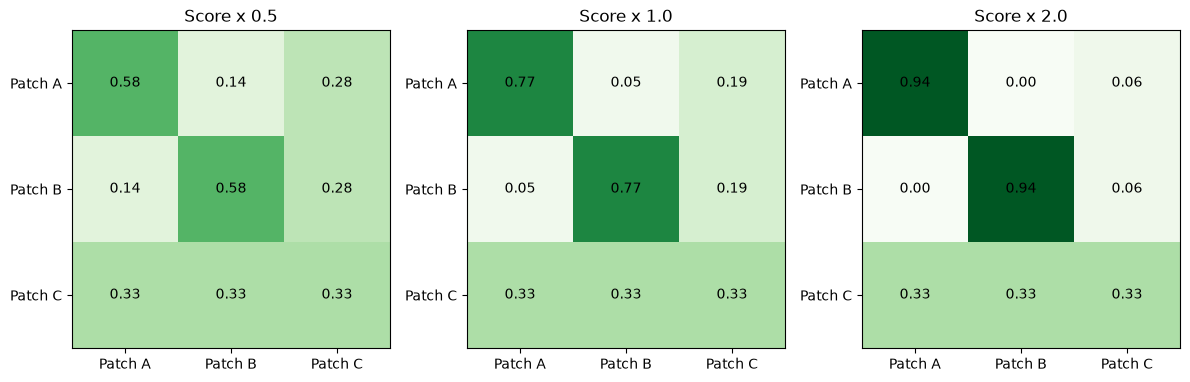

In [10]:
# 6.2 Score의 크기에 따른 Softmax 분포 비교

MULTIPLIERS = [0.5, 1.0, 2.0]
# 변경해 보기: [0.25, 1.0, 4.0]

base_scores = (Q3 @ K3.T) / math.sqrt(2)

fig, axes = plt.subplots(
    1,
    len(MULTIPLIERS),
    figsize=(4 * len(MULTIPLIERS), 4)
)

axes = np.atleast_1d(axes)

for ax, multiplier in zip(axes, MULTIPLIERS):
    current = torch.softmax(
        base_scores * multiplier,
        dim=-1
    ).numpy()

    ax.imshow(
        current,
        cmap="Greens",
        vmin=0,
        vmax=1
    )

    ax.set_title(f"Score x {multiplier}")
    ax.set_xticks(range(3), labels)
    ax.set_yticks(range(3), labels)

    for r in range(3):
        for c in range(3):
            ax.text(
                c, r,
                f"{current[r, c]:.2f}",
                ha="center",
                va="center"
            )

plt.tight_layout()
plt.show()

## 7. Patch Size와 Attention Matrix 크기

**연계 이론:** 이론 3 · 2.2, 7.4 / 이론 4 · 3.3, 6.4

Attention Matrix 크기는 Head 하나와 CLS Token을 포함한
Token 수를 기준으로 확인합니다.

In [11]:
for p in [16, 32]:
    patch_count = (224 // p)**2
    token_count = patch_count + 1  # CLS Token 포함

    print(
        f"Patch {p}: "
        f"patches={patch_count}, "
        f"tokens={token_count}, "
        f"attention shape=({token_count}, {token_count}), "
        f"entries={token_count**2:,}"
    )

assert (196 + 1)**2 == 38809
assert (49 + 1)**2 == 2500

Patch 16: patches=196, tokens=197, attention shape=(197, 197), entries=38,809
Patch 32: patches=49, tokens=50, attention shape=(50, 50), entries=2,500


## 8. 이번 실습 간단하게 요약

**첫째,** Patch Size가 커지면 동일한 이미지에서
Patch 수와 Token 수가 줄어듭니다.

**둘째,** Patch Flatten과 Linear Projection은 서로 다른 연산이며,
CLS Token을 추가한 뒤 Positional Embedding을 더합니다.

**셋째,** Q·K의 내적 → Scaling → Softmax → Value 가중합으로
새로운 Token 표현을 계산합니다.
Attention Heatmap의 행은 Query, 열은 Key입니다.

**다음 실습:** 「ResNet과 ViT의 이미지 처리 비교」